### Feature Selection
Now we will implement a feature selection pipeline. Unlike PCA which projects features into a lower-dimensional space, feature selection helps us keep the most informative original features.

In [10]:
from sklearn.feature_selection import SelectKBest, f_classif
import pandas as pd
import numpy as np

# Assuming you have your features in X and target in y
# Let's create a placeholder demonstration. Replace X and y with your variables.
# For example:
# X = df.drop(columns=['target'])
# y = df['target']

# Defining placeholder data for demo purposes
np.random.seed(42)
X_demo = pd.DataFrame(np.random.rand(100, 10), columns=[f'feature_{i}' for i in range(10)])
y_demo = np.random.choice([0, 1], size=100)

# Select the top 5 most important features
selector = SelectKBest(score_func=f_classif, k=5)
X_new = selector.fit_transform(X_demo, y_demo)

# Get selected feature names
selected_features = X_demo.columns[selector.get_support()]
print("Selected Features:", list(selected_features))


Selected Features: ['feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_8']


### Feature Selection, PCA, and Variance Visualization on Cleaned Diabetes Dataset

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
df = pd.read_csv('/content/cleaned_diabetes_data.csv')
print("Dataset shape:", df.shape)

# Separate target (y)
target_col = df.columns[-1]
y = df[target_col]

# Drop non-numeric metadata columns like 'user_id' and 'date' before doing scaling, PCA and Feature Selection
# We will only keep columns with numeric types
X_raw = df.drop(columns=[target_col])
X = X_raw.select_dtypes(include=[np.number])

# If 'user_id' or 'id' are numerical but are actually identifiers, we drop them too
columns_to_drop = [col for col in X.columns if 'id' in col.lower() or 'index' in col.lower()]
if columns_to_drop:
    print(f"Dropping identifier columns: {columns_to_drop}")
    X = X.drop(columns=columns_to_drop)

# Scale the features (important for PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Processed feature space shape:", X.shape)
print(f"Target column identified: '{target_col}'")

Dataset shape: (1000, 13)
Dropping identifier columns: ['user_id']
Processed feature space shape: (1000, 10)
Target column identified: 'risk_score'


In [12]:
# 2. Feature Selection using SelectKBest with cleaned numeric features X
num_features_to_select = min(5, X.shape[1])
selector = SelectKBest(score_func=f_classif, k=num_features_to_select)
X_selected = selector.fit_transform(X, y)

selected_cols = X.columns[selector.get_support()]
print(f"Top {num_features_to_select} Selected Features:", list(selected_cols))

Top 5 Selected Features: ['weight', 'blood_glucose', 'physical_activity', 'medication_adherence', 'bmi']


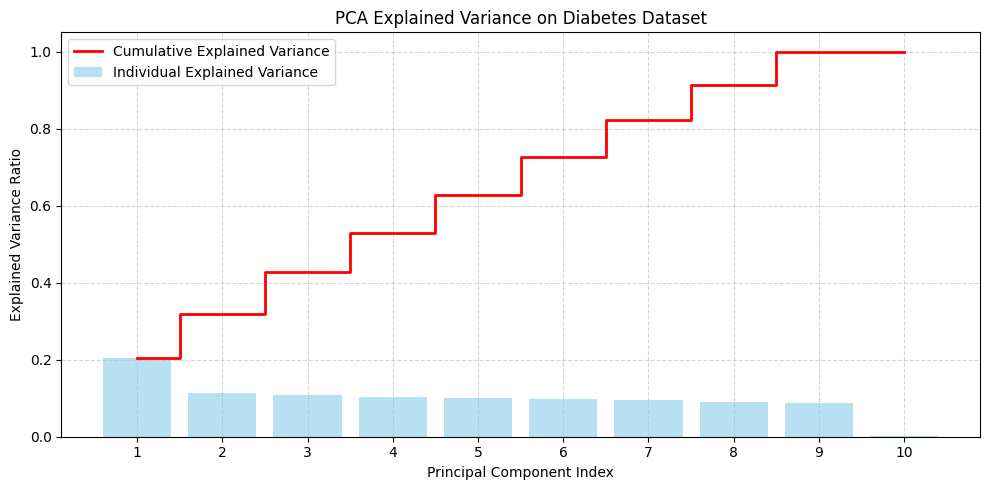

In [13]:
# 3. PCA & Variance Visualization
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Calculate explained variance ratios
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Visualization
plt.figure(figsize=(10, 5))

# Plot individual explained variance
plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.6, align='center', label='Individual Explained Variance', color='skyblue')

# Plot cumulative explained variance
plt.step(range(1, len(cumulative_variance) + 1), cumulative_variance, where='mid', label='Cumulative Explained Variance', color='red', linewidth=2)

plt.ylabel('Explained Variance Ratio')
plt.xlabel('Principal Component Index')
plt.title('PCA Explained Variance on Diabetes Dataset')
plt.xticks(range(1, len(explained_variance) + 1))
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Analyzing Principal Components (PCs) One by One
Let's extract and look at the loading scores (coefficients) of each feature for each Principal Component to understand what each PC represents.

In [14]:
# Create a DataFrame showing the feature weight (loading) in each Principal Component
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(pca.n_components_)],
    index=X.columns
)

# Display the full loadings table
print("--- Feature Loadings for all Principal Components ---")
display(loadings.round(3))


--- Feature Loadings for all Principal Components ---


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
weight,0.602,0.111,-0.185,0.228,0.219,0.081,-0.041,-0.063,0.323,-0.612
height,-0.373,0.136,-0.229,0.414,0.362,0.243,-0.054,-0.202,0.518,0.341
blood_glucose,0.037,-0.371,0.012,-0.254,0.422,0.672,-0.101,0.367,-0.146,0.002
physical_activity,0.031,-0.346,0.588,0.080,0.013,-0.075,0.551,0.135,0.446,-0.001
diet,-0.061,-0.361,-0.392,0.479,-0.084,-0.307,-0.011,0.614,-0.066,0.003
medication_adherence,0.071,-0.256,0.464,0.534,0.219,-0.058,-0.359,-0.311,-0.390,0.003
stress_level,-0.055,0.117,-0.020,-0.256,0.763,-0.552,0.116,0.069,-0.112,0.003
sleep_hours,0.016,0.531,0.069,0.355,0.071,0.266,0.542,0.188,-0.427,0.002
hydration_level,0.042,-0.468,-0.437,-0.007,0.030,0.041,0.495,-0.535,-0.232,0.002
bmi,0.694,0.032,-0.048,-0.005,0.009,-0.046,-0.010,0.040,0.035,0.714
